# Attention to the first token

The read-only probe uses the same 32 random 256-token validation windows
for three full-attention checkpoints. Their first tokens are ordinary corpus
tokens, with zero EOS starts. Summary queries are positions 64–255, excluding
the forced self-attention at position zero. Keys 0–63 are visible to all of
these queries. Source is in `experiments/attention/inspect_sinks.py`; it checks
reconstructed logits against the normal model forward call. These cells load
saved results and require only the analysis environment.

## Interactive attention maps

Start the local viewer from the repository root and leave the terminal running.

```sh
.venv/bin/python experiments/attention/serve_viewer.py
```

Open [the attention explorer](http://127.0.0.1:8765/). Select a checkpoint, layer and head. Wheel to zoom at the pointer, drag to pan, or use the position overview to reach a region. Fit restores the whole map. Full screen gives more viewing space. Hover reads exact averaged probabilities. The app loads the current saved probe arrays when you refresh probes.


## Which heads focus on the first token?

Each square represents one attention head in one layer. Rows are layers
1–4 from top to bottom, and columns are heads 1–4. The number inside a square
is the percentage of that head’s attention assigned to **key position 0**,
averaged over 32 windows and query positions 64–255. Every row uses the
same color scale, from pale yellow at 0% to dark red at 30%.

For example, **19.9% in layer 2, head 3** means that almost one fifth of
that head’s probability goes to the first token when processing later tokens.
Heads distribute their remaining probability among other visible tokens.
Uniform causal attention would give position zero about **0.72%** here.
Look for isolated dark squares to identify heads with a large preference.
Compare checkpoints with care because the RoPE model trained for fewer tokens.

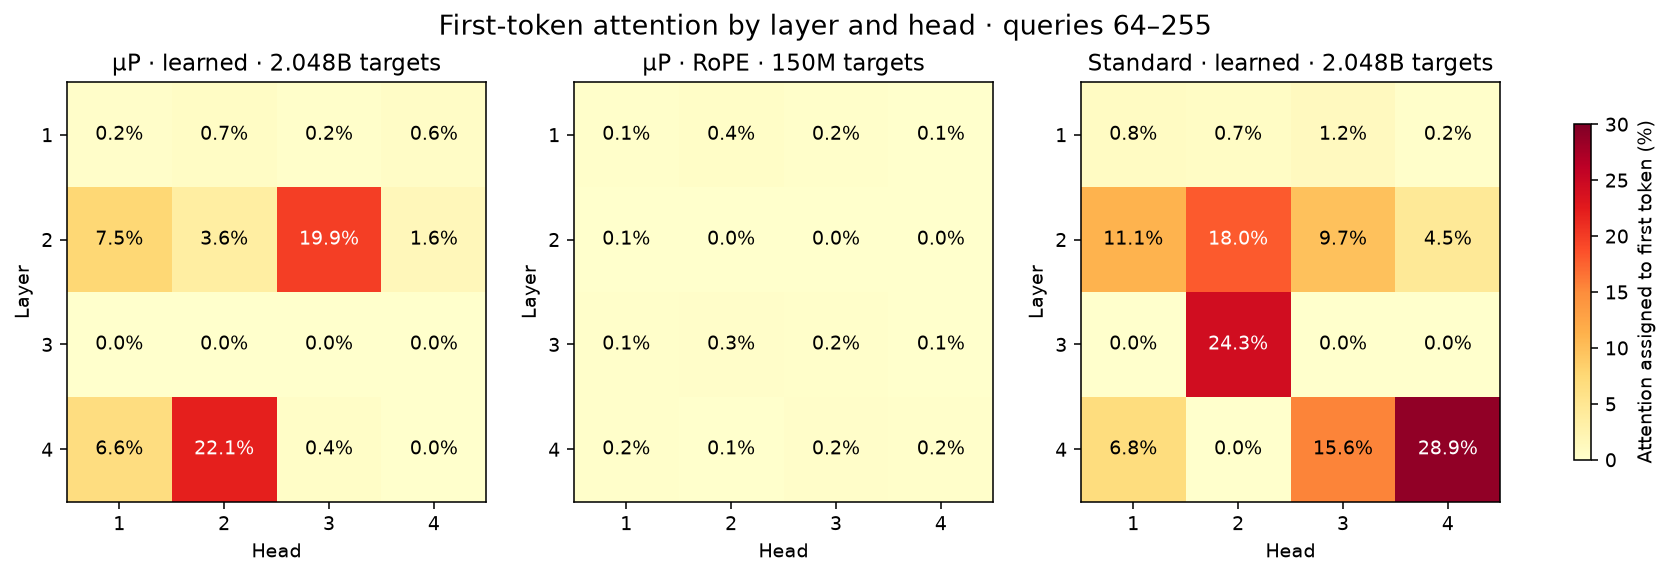

In [1]:
import json
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
root = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / "pyproject.toml").is_file())
data = root / "artifacts/analysis/attention-sinks"
summaries = json.loads((data / "summary.json").read_text())
names = ["μP · learned · 2.048B targets", "μP · RoPE · 150M targets", "Standard · learned · 2.048B targets"]
fig, axes = plt.subplots(1, 3, figsize=(12, 4), layout="constrained")
for ax, row, name in zip(axes, summaries, names):
    mass = np.array(row["first_mass"]) * 100
    image = ax.imshow(mass, vmin=0, vmax=30, cmap="YlOrRd")
    for (layer, head), value in np.ndenumerate(mass):
        ax.text(head, layer, f"{value:.1f}%", ha="center", va="center",
                color="white" if value > 18 else "black", fontsize=10)
    ax.set(title=name, xlabel="Head", ylabel="Layer",
           xticks=range(4), xticklabels=range(1,5), yticks=range(4), yticklabels=range(1,5))
fig.colorbar(image, ax=axes, label="Attention assigned to first token (%)", shrink=.8)
fig.suptitle("First-token attention by layer and head · queries 64–255", fontsize=14)
fig.savefig(data / "first-position-heads.png", dpi=170)
plt.show()

## Is the preference specific to position zero?

The horizontal axis is the position of the **key token being attended to**,
from 0 to 63. The vertical axis is its mean share of attention in percent,
averaged over every layer, head, window and late query (positions 64–255).
All 64 plotted keys are visible to all these queries.

The orange point highlights position zero. The dashed line shows the
**0.72% uniform-attention reference** for each early key. A large spike at
zero compared with positions 1–15 indicates a preference for the window’s
first token, beyond simply preferring early tokens. Averaging across heads
makes this spike smaller than the strongest individual heads in the first
figure. The shared vertical scale lets you compare its size across models.

The learned-position models have a sharp first-position spike. In the RoPE
model, position zero looks similar to its early neighbors.

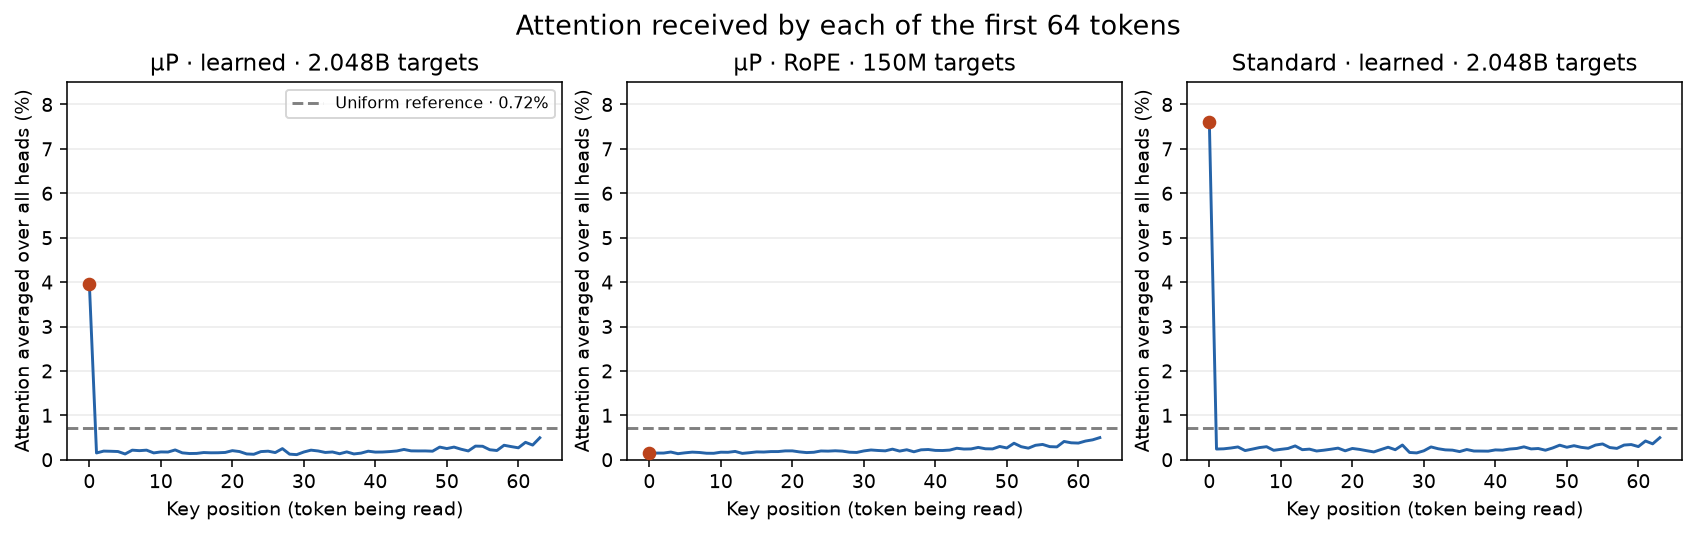

In [2]:
fig, axes = plt.subplots(1, 3, figsize=(12, 3.7), layout="constrained")
for ax, row, name in zip(axes, summaries, names):
    maps = np.load(data / f'{row["run"]}.npz')["attention"]
    profile = maps[:, :, 64:, :64].mean((0,1,2))
    ax.plot(range(64), profile * 100, color="#2563a8")
    ax.scatter(0, profile[0]*100, color="#bb431b", zorder=4)
    ax.axhline(row["uniform_first_mass"]*100, ls="--", color="gray", label="Uniform reference · 0.72%")
    ax.set(title=name, xlabel="Key position (token being read)", ylabel="Attention averaged over all heads (%)", ylim=(0, 8.5))
    ax.grid(axis="y", alpha=.25)
axes[0].legend(fontsize=8)
fig.suptitle("Attention received by each of the first 64 tokens", fontsize=14)
fig.savefig(data / "early-position-profiles.png", dpi=170)
plt.show()

## Where does a strongly first-focused head look?

Each panel shows the head with the **largest measured first-position mass**
in that checkpoint. The title identifies its layer (L) and head (H).
These are different selected heads across models.

A row corresponds to a **query position** (the token doing the reading).
A column corresponds to a **key position** (the token it reads from).
The top-left corner is query 0 reading key 0. Moving down follows later queries.
Each cell averages attention probability over the 32 validation windows.

Brighter colors mean more attention, with the same scale in all panels.
Values above 0.3 use the brightest color. The dark upper-right triangle is
future tokens excluded by the causal mask. A bright diagonal means attention
to the current token. A bright vertical stripe at column zero means many
queries keep reading the first token. The bright top-left cell occurs
automatically because query zero can attend only to itself.

In the learned-position panels, inspect the left edge below query 64 for a
persistent stripe. The RoPE panel is its most first-focused head too, but it
still gives little mass to position zero on late queries.

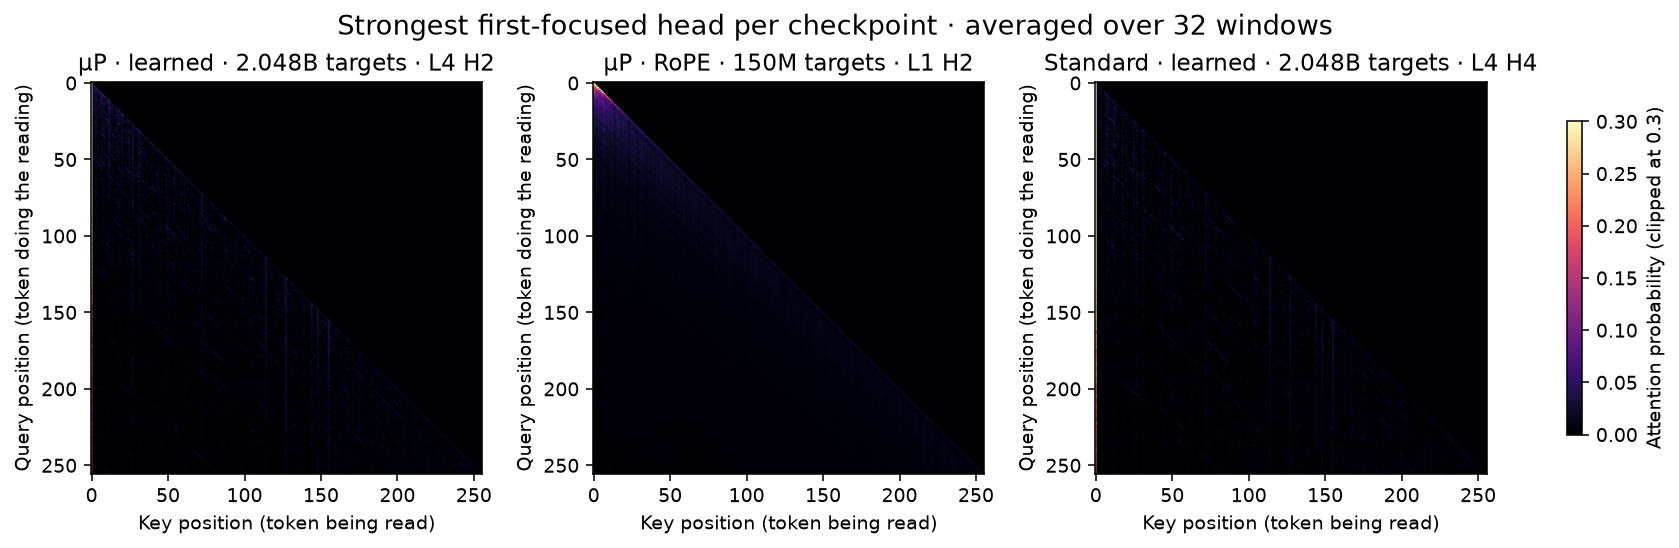

In [3]:
fig, axes = plt.subplots(1, 3, figsize=(12, 3.8), layout="constrained")
for ax, row, name in zip(axes, summaries, names):
    layer, head = np.unravel_index(np.argmax(row["first_mass"]), (4,4))
    maps = np.load(data / f'{row["run"]}.npz')["attention"]
    image = ax.imshow(maps[layer,head], origin="upper", cmap="magma", vmin=0, vmax=.3)
    ax.set(title=f"{name} · L{layer+1} H{head+1}", xlabel="Key position (token being read)", ylabel="Query position (token doing the reading)")
fig.colorbar(image, ax=axes, label="Attention probability (clipped at 0.3)", shrink=.8)
fig.suptitle("Strongest first-focused head per checkpoint · averaged over 32 windows", fontsize=14)
fig.savefig(data / "attention-maps.png", dpi=170)
plt.show()

The learned-position μP model gives position zero **3.96%** attention overall
versus **0.176% per key** for positions 1–15. Layer 2 head 3 gives it **19.88%**
and ranks it first in **100%** of sampled late queries. Layer 4 head 2 gives
it **22.14%**. The standard learned-position model gives position zero **7.60%**
overall and also has several heads with a marked preference.

The RoPE checkpoint gives position zero **0.152%**, versus **0.159% per key**
for positions 1–15. It shows no comparable position-zero preference here.
The uniform causal reference is **0.719%** per early key. Because all keys
0–63 are visible to all sampled queries, the learned models' spikes exceed
the effect of causal visibility alone.

Attention probabilities reveal a position preference. Value contributions
and ablations would establish whether the model uses it as a sink. The
checkpoints have different training histories, and the standard model also
has tied embeddings and a different training recipe. They do not isolate
the effect of RoPE. The probe covers fixed windows rather than the whole corpus.

# General attention overview

These figures use the saved 32 validation windows. No heads are selected for
first-token behavior. Read the position maps alongside the distance summaries
to distinguish local attention, broad attention, and fixed-position patterns.
The same three checkpoints are shown throughout. Their training histories differ.

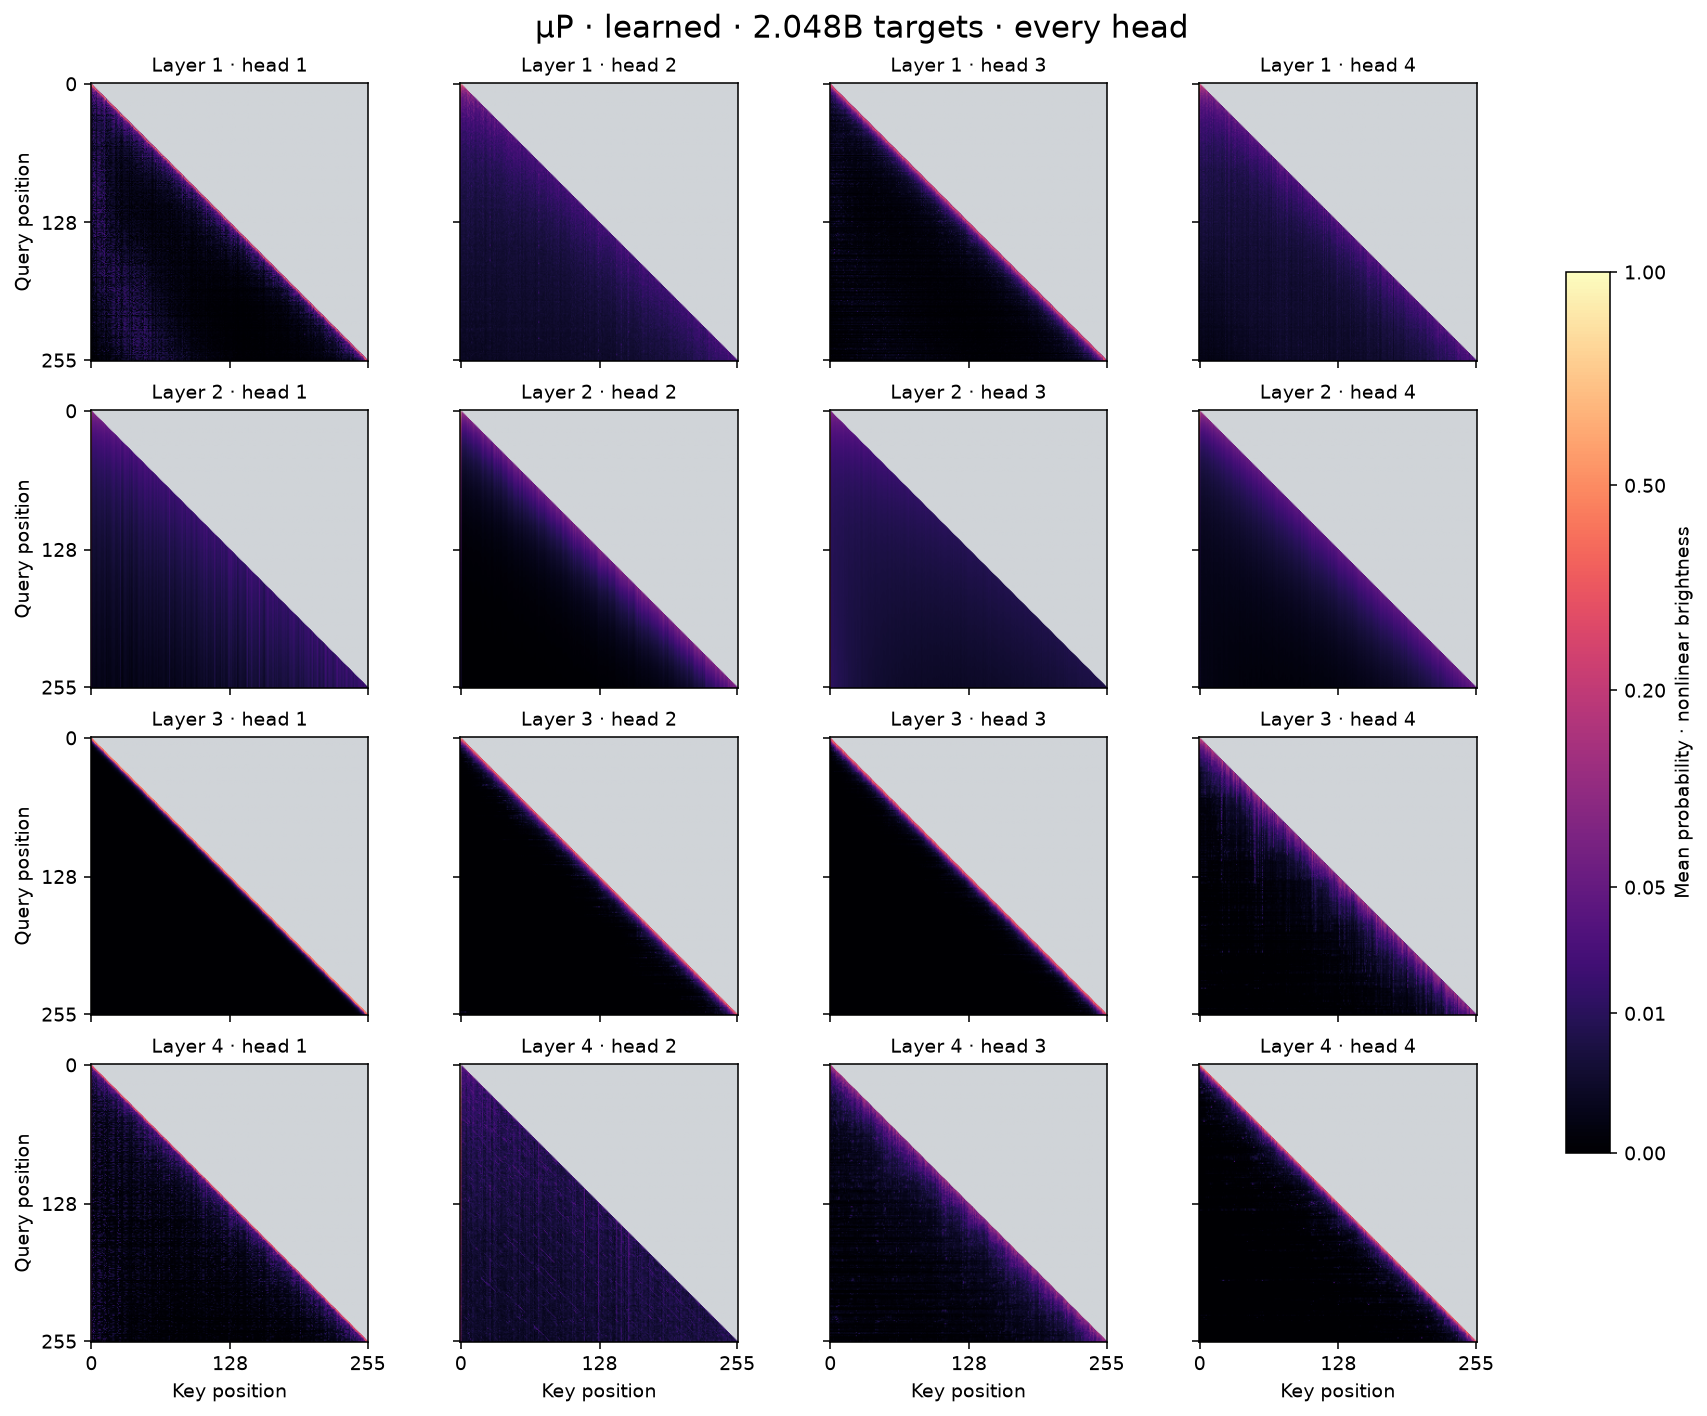

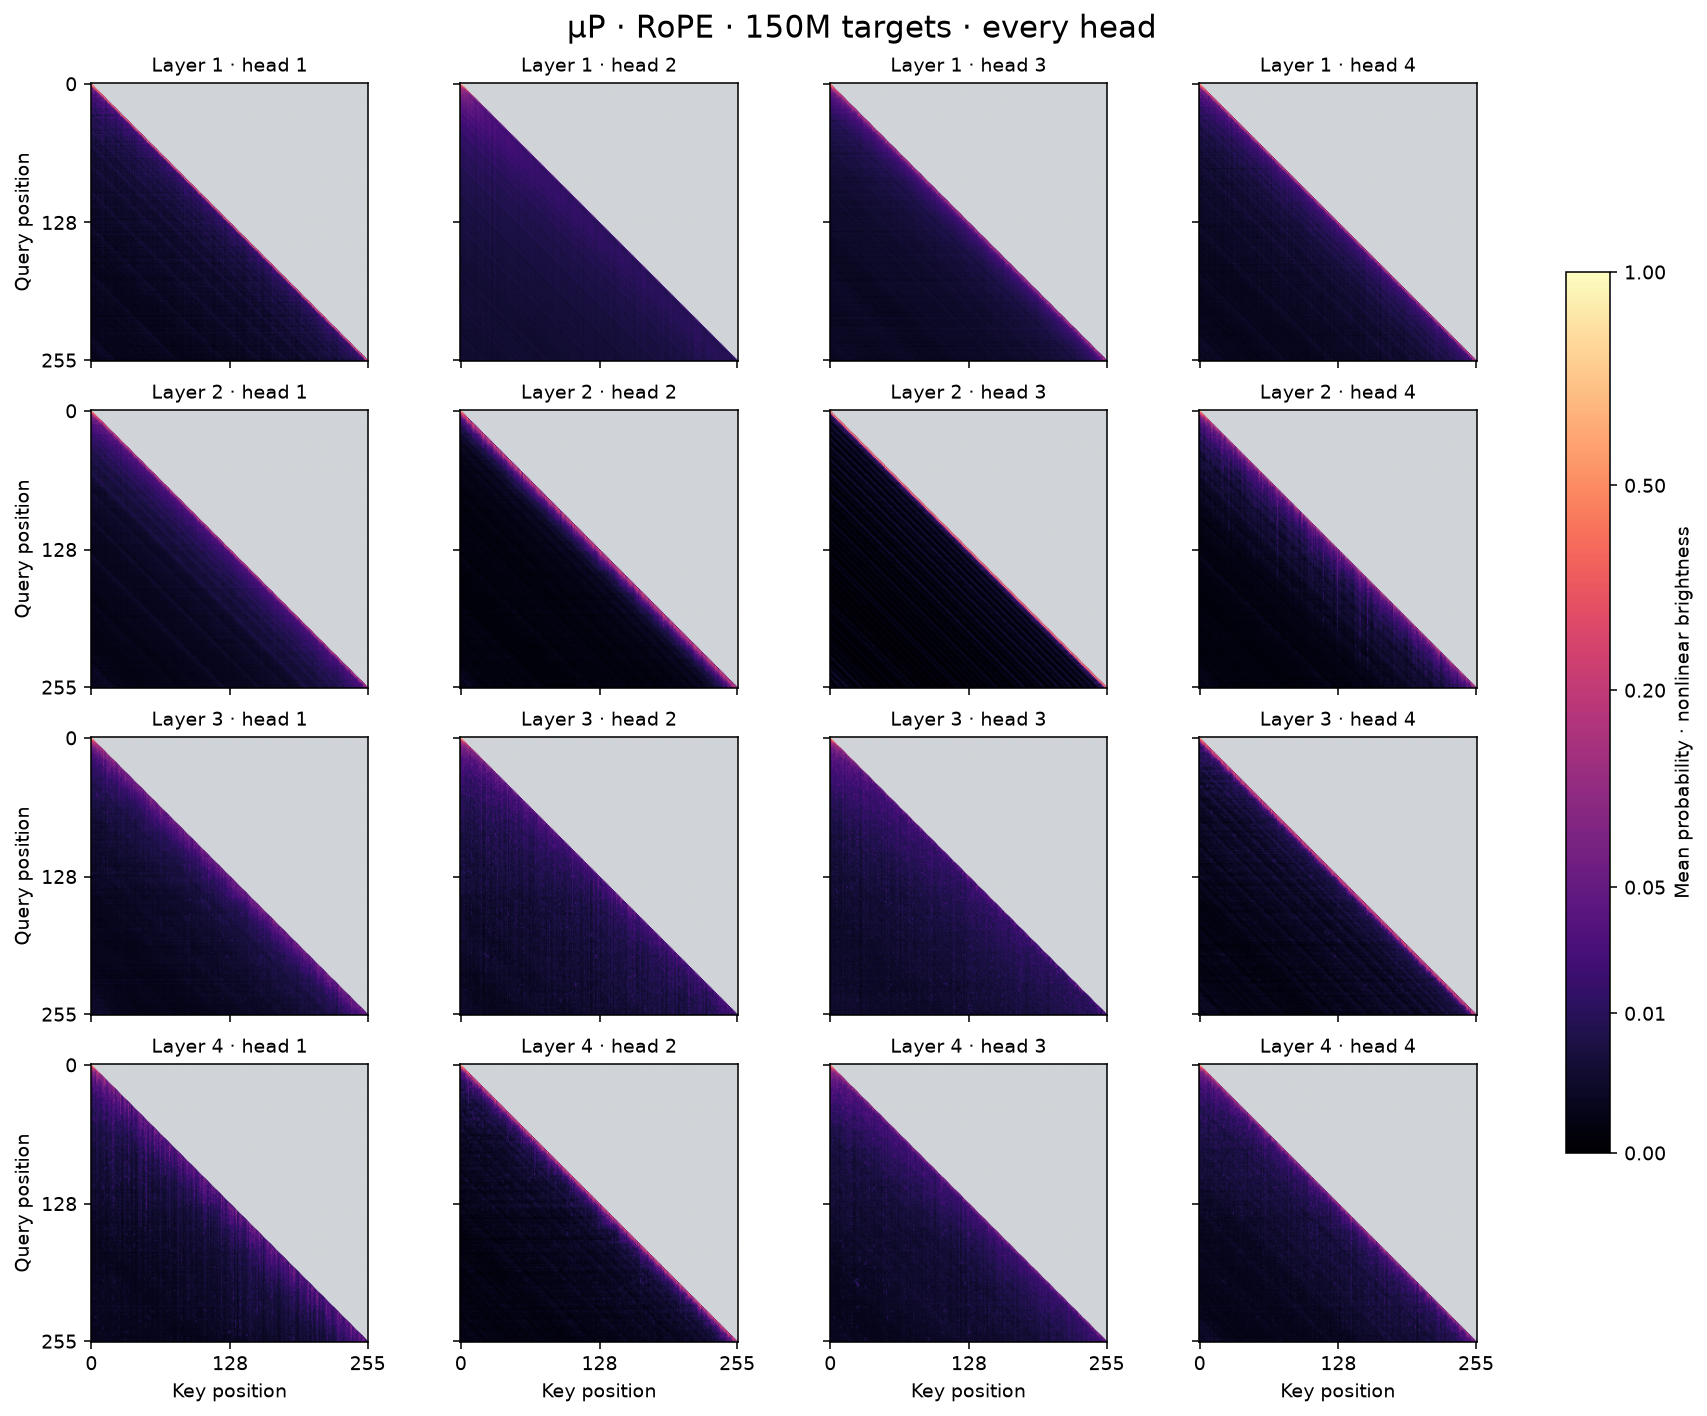

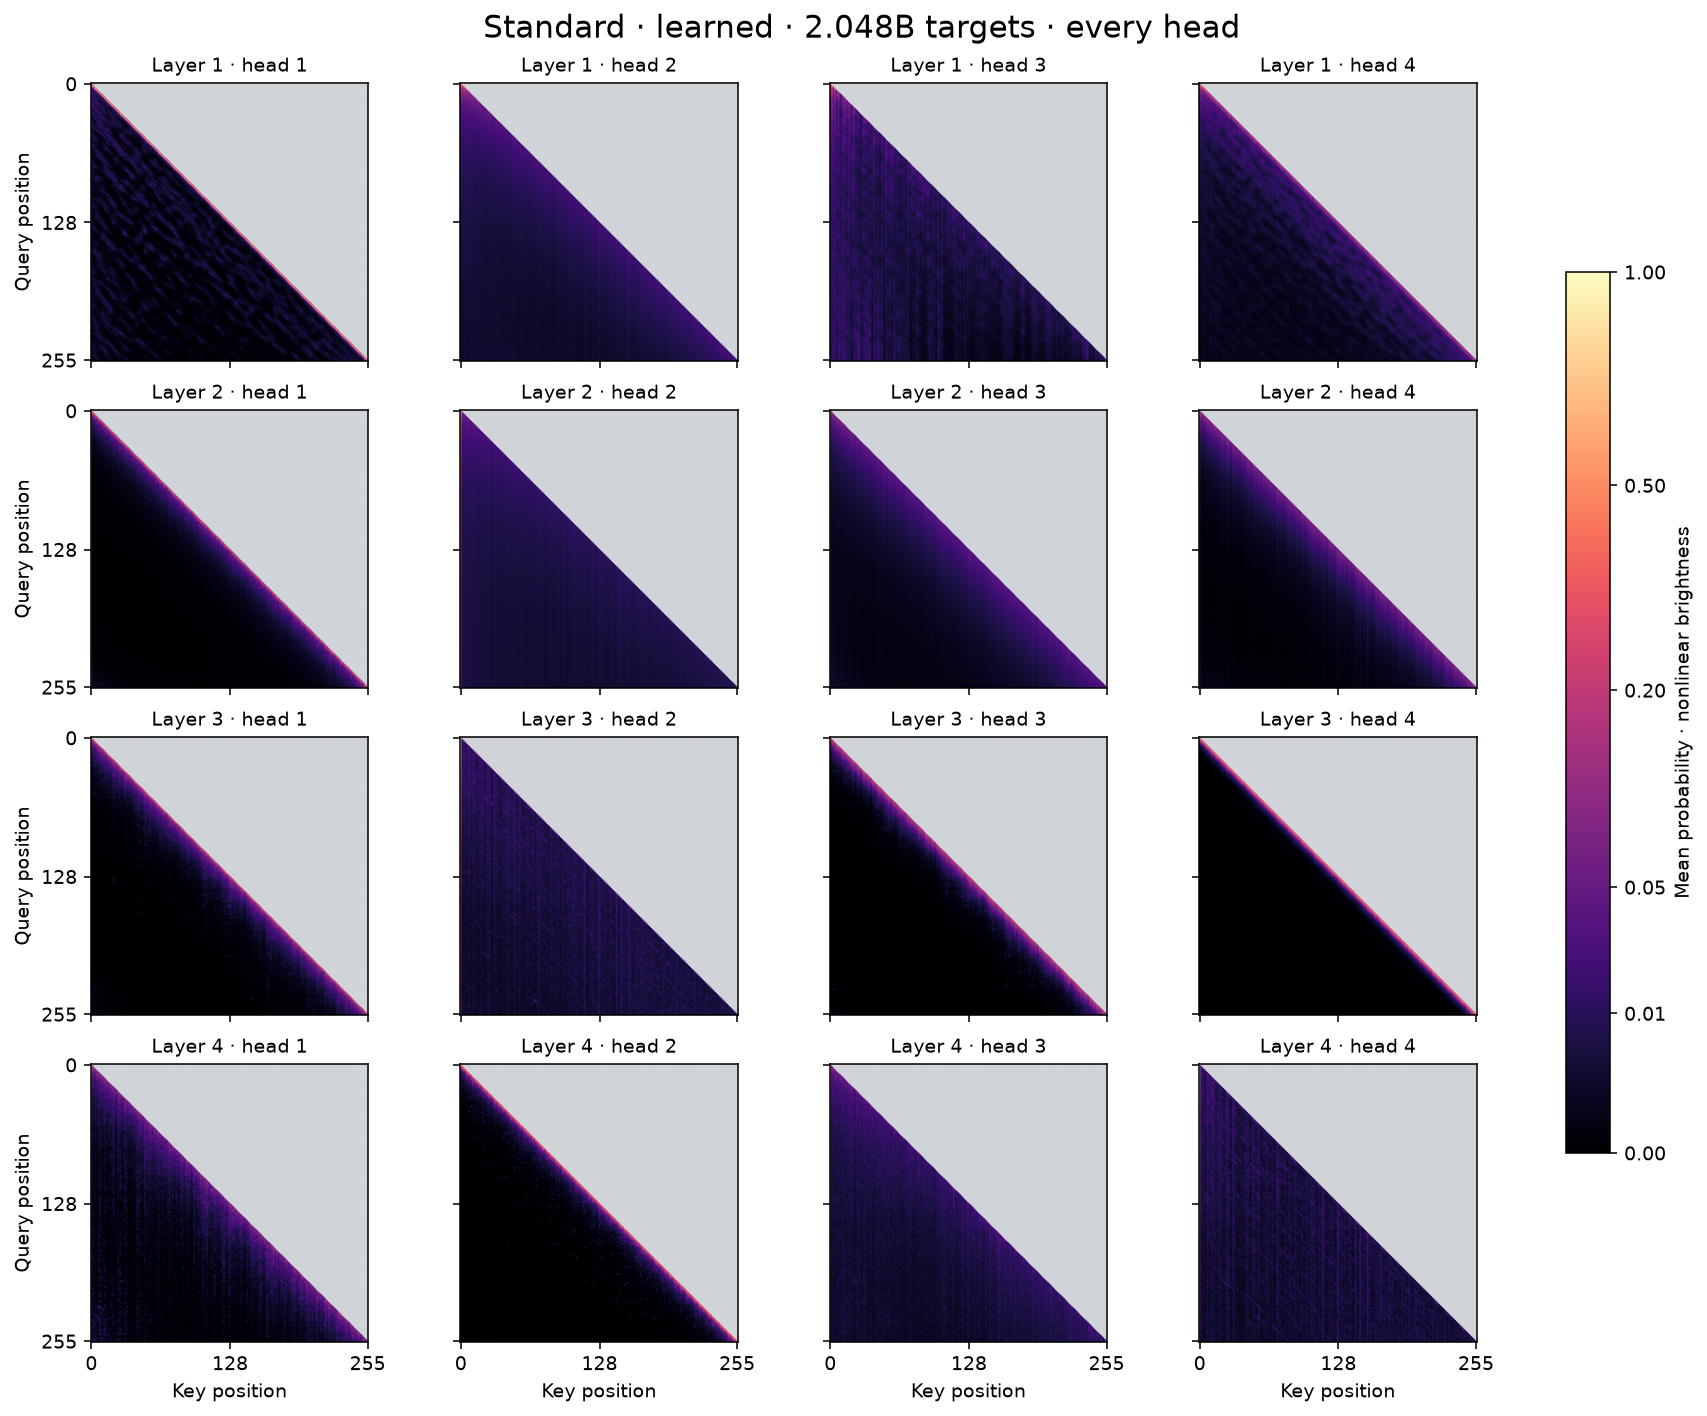

In [4]:
maps_by_run = [np.load(data / f'{row["run"]}.npz')["attention"] for row in summaries]
from matplotlib.colors import PowerNorm
positions = np.arange(256)
future = positions[None, :] > positions[:, None]
cmap = plt.get_cmap("magma").copy()
cmap.set_bad("#d0d4d8")
for maps, name, row in zip(maps_by_run, names, summaries):
    fig, axes = plt.subplots(4, 4, figsize=(12, 10), sharex=True, sharey=True, layout="constrained")
    for (layer, head), ax in np.ndenumerate(axes):
        image = ax.imshow(np.ma.array(maps[layer, head], mask=future),
                          norm=PowerNorm(gamma=.4, vmin=0, vmax=1), cmap=cmap, origin="upper")
        ax.set_title(f"Layer {layer+1} · head {head+1}", fontsize=10)
        ax.set_xticks([0, 128, 255])
        ax.set_yticks([0, 128, 255])
        if layer == 3: ax.set_xlabel("Key position")
        if head == 0: ax.set_ylabel("Query position")
    fig.colorbar(image, ax=axes.ravel().tolist(), label="Mean probability · nonlinear brightness", shrink=.7,
                 ticks=[0, .01, .05, .2, .5, 1])
    fig.suptitle(name + " · every head", fontsize=16)
    fig.savefig(data / f'{row["run"]}-all-heads.png', dpi=150)
    plt.show()

**Reading the all-head maps.** Each row of small panels is a layer and each
column is a head. Inside a panel, the horizontal axis is key position and the
vertical axis is query position. Gray cells are masked future positions.
A bright diagonal indicates attention to the current token or its immediate
neighbors. Broad filled triangles indicate more distributed attention. Vertical
bands indicate preference for fixed positions.

Every panel shares a nonlinear brightness scale over probabilities 0–1. This
makes weak attention visible while retaining high-probability cells. Maps average
different token content across 32 windows, so they emphasize consistent positional
patterns rather than individual semantic relationships.

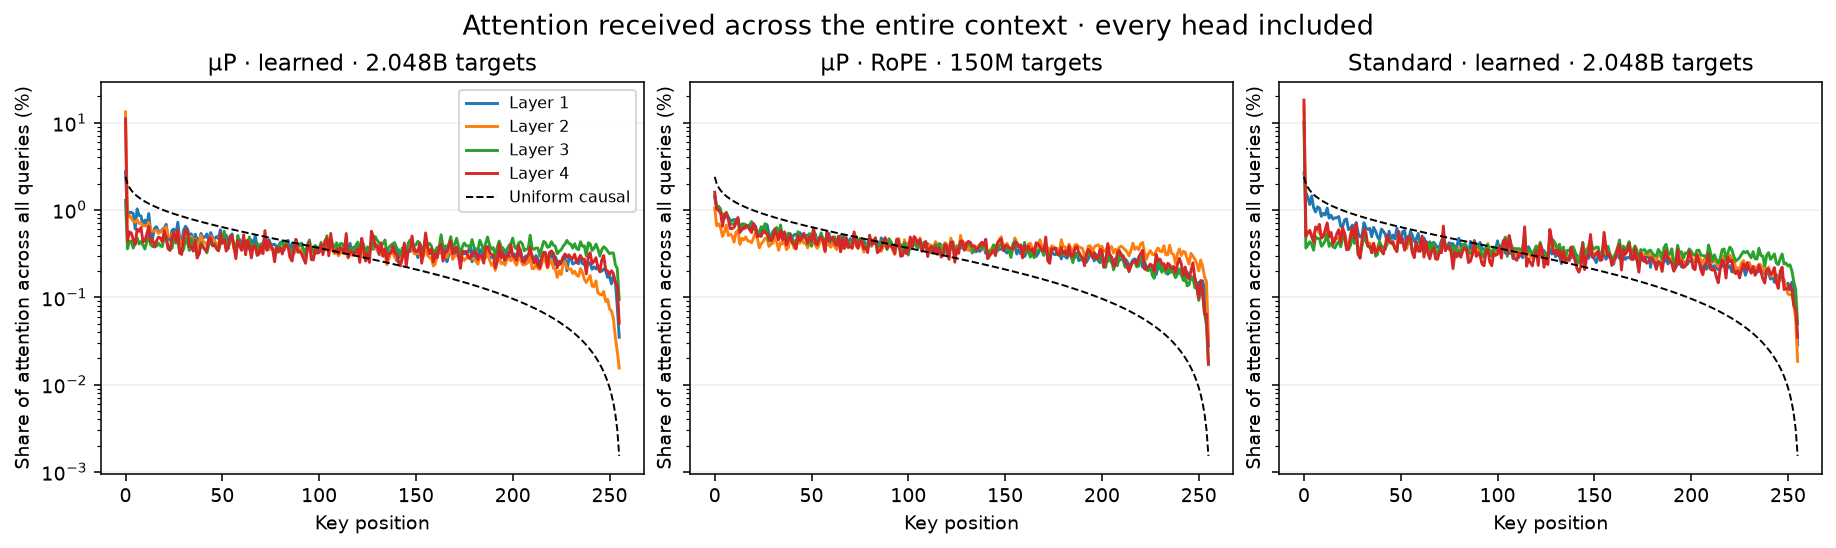

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.8), sharey=True, layout="constrained")
for ax, maps, name in zip(axes, maps_by_run, names):
    for layer in range(4):
        # Each query contributes equal total mass; the curve sums to one.
        received = maps[layer].mean((0, 1))
        ax.plot(positions, received * 100, label=f"Layer {layer+1}")
    uniform = np.array([np.mean([1/(q+1) if k <= q else 0 for q in positions])
                        for k in positions])
    ax.plot(positions, uniform*100, ls="--", color="black", lw=1, label="Uniform causal")
    ax.set(title=name, xlabel="Key position", ylabel="Share of attention across all queries (%)",
           yscale="log")
    ax.grid(axis="y", alpha=.2)
axes[0].legend(fontsize=8)
fig.suptitle("Attention received across the entire context · every head included", fontsize=14)
fig.savefig(data / "all-position-profiles.png", dpi=170)
plt.show()

**Reading the full-context profiles.** Each line is a layer, averaging its
four heads, 32 windows, and all queries. The vertical axis is logarithmic so
small shares remain visible. Early keys can be read by more queries, which
naturally raises their received share. The dashed line shows that visibility
effect under uniform causal attention. Differences from it show where layers
concentrate attention. Later keys have fewer eligible queries, so a low received
share alone does not imply that the model ignores them.

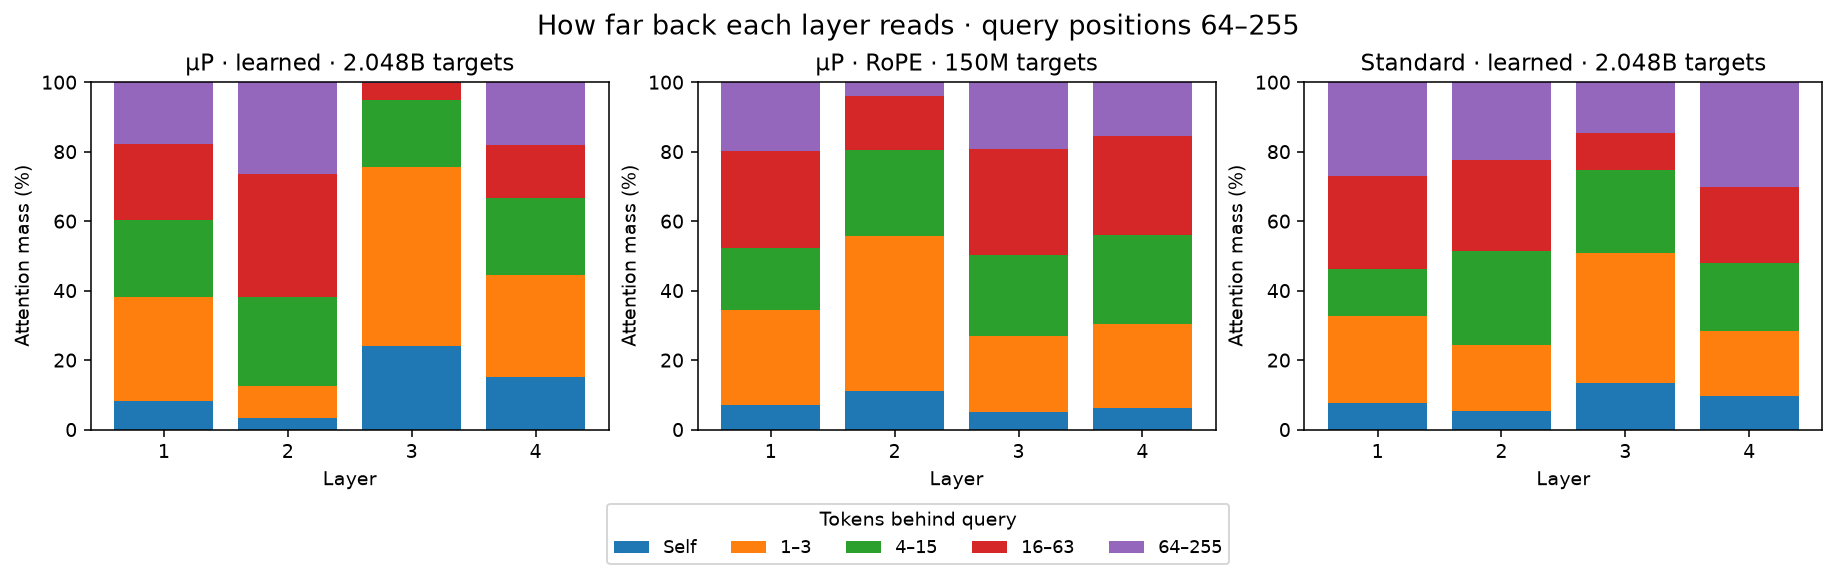

In [6]:
edges = [0, 1, 4, 16, 64, 256]
labels = ["Self", "1–3", "4–15", "16–63", "64–255"]
fig, axes = plt.subplots(1, 3, figsize=(13, 4), layout="constrained")
for ax, maps, name in zip(axes, maps_by_run, names):
    # Use late queries for all bins, so every query has at least 65 visible keys.
    mass = np.zeros((4, len(labels)))
    for layer in range(4):
        for query in range(64, 256):
            values = maps[layer, :, query, :query+1].mean(0)[::-1]
            for index, (start, stop) in enumerate(zip(edges[:-1], edges[1:])):
                mass[layer, index] += values[start:stop].sum() / 192
    np.testing.assert_allclose(mass.sum(1), 1, atol=1e-6)
    bottom = np.zeros(4)
    for index, label in enumerate(labels):
        ax.bar(np.arange(1, 5), mass[:, index]*100, bottom=bottom*100, label=label)
        bottom += mass[:, index]
    ax.set(title=name, xlabel="Layer", ylabel="Attention mass (%)", xticks=range(1, 5), ylim=(0,100))
fig.legend(*axes[0].get_legend_handles_labels(), title="Tokens behind query",
           loc="outside lower center", ncol=5, fontsize=9)
fig.suptitle("How far back each layer reads · query positions 64–255", fontsize=14)
fig.savefig(data / "attention-distance.png", dpi=170)
plt.show()

**Reading the distance bars.** Each layer’s bar sums to 100% attention.
Segments group keys by how many positions they precede the query. “Self” is
distance zero, and “1–3” contains the three immediately preceding tokens.
These are total mass per distance bin, so the wider bins contain more keys.
This view reveals local versus distant attention, averaged over all heads,
without privileging any absolute position. It still includes genuine attention
to the first token whenever it falls in the relevant distance bin.

Together these views describe positional structure in attention probabilities.
They do not directly measure each head’s contribution to the model output.